<a href="https://colab.research.google.com/github/MSGamgee85/Projetos/blob/main/Simulacao_Monte_Carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  ![Google Colab](https://img.shields.io/badge/Google%20Colab-%23F9A825.svg?style=for-the-badge&logo=googlecolab&logoColor=black) ![NumPy](https://img.shields.io/badge/numpy-%23013243.svg?style=for-the-badge&logo=numpy&logoColor=white) ![GitHub](https://img.shields.io/badge/github-%23121011.svg?style=for-the-badge&logo=github&logoColor=white)

  ---
  ## **Simulação de Monte Carlo** 🎲 🎲 🎲
  ---

A *simulação de Monte Carlo* é uma poderosa ferramenta matemática que permite prever e compreender o comportamento de diversos sistemas e consiste no uso de **amostras aleatórias** para estimar **resultados**. Pode ser utilizado tanto em problemas <u> determinísticos quanto estocásticos</u> e tem inúmeras aplicações nas áreas de economia e finanças.



O nome do método é uma homenagem ao **Casino de Monte Carlo**, localizado no Principado de Mônaco e foi batizado pelo seu principal criador, o matemático polonês [Stanislaw Ulam](https://en.wikipedia.org/wiki/Stanis%C5%82aw_Ulam), que desenvolveu a técnica inspirado pelos hábitos de jogatina do seu tio.



Neste notebook vamos apresentar e desenvolver duas **aplicações simples** da Simulação de Monte Carlo:

* a estimativa do valor de $\pi$ e
* análise dos indicadores de desempenho (risco e retorno) de uma carteira de investimento com um único ativo.


## **Referências**
---

Geeks For Geeks. **What is Monte Carlo Simulation?** Disponível em < https://www.geeksforgeeks.org/artificial-intelligence/what-is-monte-carlo-simulation/ >. Acesso em: 16 nov. 2026

Geeks For Geeks. **Data Analysis using Monte Carlo.** Disponível em: < https://www.geeksforgeeks.org/data-analysis/data-analysis-using-monte-carlo-simulation/ > . Acesso em: 17 nov. 2026

Wikipedia. **Monte Carlo method.** Disponível em < https://en.wikipedia.org/wiki/Monte_Carlo_method >. Acesso em: 17 nov. 2026.

## **0. Configuração do ambiente**
---

In [ ]:
# -- Bibliotecas utilizadas --
import numpy as np               # funções matemáticas e operações com arrays [vetores e matrizes]
import matplotlib.pyplot as plt  # geração e visualização de gráficos
import pandas as pd              # estruturas tabulares de organização e análise de dados

## **1. Estimando o valor de $\pi$**
---

In [ ]:
# -- Construção função de Monte Carlo para estimar o valor de π --
def monte_carlo_pi(num_amostras):

    x = np.random.uniform(-1, 1, num_amostras)           # gera números aleatórios entre -1 e 1 e armazena na variável x (coordenada horizontal)
    y = np.random.uniform(-1, 1, num_amostras)           # gera números aleatórios entre -1 e 1 e armazena na variável y (coordenada vertical)
    distancia = np.sqrt(x**2 + y**2)                     # calcula a distância geométrica entre os pontos (x,y) e a origem (0,0) usando Pitágoras: raiz(x²+y²)
    dentro_circulo = np.sum(distancia <= 1)              # soma todos os casos (pontos) em que a distância geométrica é menor ou igual a 1 (dentro do círculo)
    estimativa_pi = (dentro_circulo / num_amostras) * 4  # estima o valor de pi a partir da razão entre as áreas do círculo (raio = 1) e do quadrado (lado = 2)
    return estimativa_pi                                 # apresenta o valor calculado para pi

In [ ]:
# -- Simulação de Monte Carlo - estimativa valor de π --
num_amostras = 10000                                                                # número de pontos para a simulação
estimativa_pi = monte_carlo_pi(num_amostras)                                        # chama a função de Monte Carlo
print('-' * 52)                                                                     # linha horizontal no formato ---
print(f"O valor estimado de π com {num_amostras} amostras é: {estimativa_pi:.5f}")  # imprime o resultado com 5 casas decimais
print('-' * 52)                                                                     # linha horizontal no formato ---

----------------------------------------------------
O valor estimado de π com 10000 amostras é: 3.12760
----------------------------------------------------


In [ ]:
# -- Indicadores de desempenho da simulação --
pi_real = np.pi                                             # valor real de pi

# Cálculo dos erros
erro_absoluto = abs(estimativa_pi - pi_real)                # calcula o erro absoluto
erro_relativo_percentual = (erro_absoluto / pi_real) * 100  # calcula o erro relativo em %

# Exibição dos resultados
print("Simulação de Monte Carlo - Erro da Estimativa")      # título
print("=" * 45)                                             # linha horizontal no formato ===
print(f"Valor Real de π: {pi_real:.5f}")                    # mostra o valor de π com 5 casas decimais
print(f"Valor Estimado:  {estimativa_pi:.5f}")              # mostra o valor estimado de π com 5 casas decimais
print(f"Erro Absoluto:   {erro_absoluto:.5f}")              # mostra o valor do erro absoluto com 5 casas decimais
print(f"Erro Relativo:   {erro_relativo_percentual:.2f}%")  # mostra o valor do erro relativo percentual com 2 casas decimais
print("=" * 45)                                             # linha horizontal no formato ===

Simulação de Monte Carlo - Erro da Estimativa
Valor Real de π: 3.14159
Valor Estimado:  3.12760
Erro Absoluto:   0.01399
Erro Relativo:   0.45%


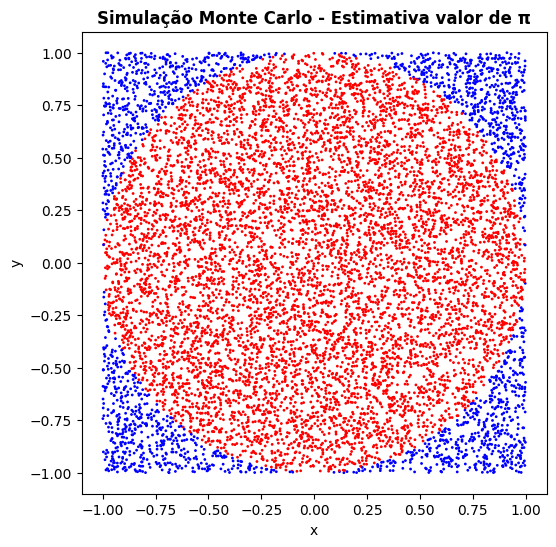

In [ ]:
# -- Geração e visualização do gráfico --
x = np.random.uniform(-1, 1, num_amostras)  # gera pontos aleatórios da coordenada horizontal
y = np.random.uniform(-1, 1, num_amostras)  # gera pontos aleatórios da coordenada vertical

plt.figure(figsize=(6, 6))                                                     # gera uma figura de 6x6 pols
plt.scatter(x, y, c=np.sqrt(x**2 + y**2) <= 1, cmap='bwr', s=1)                # gera gráfico de pontos com regra de coloração do círculo; bwr = blue, white, red; s = size [tamanho do ponto]
plt.title('Simulação Monte Carlo - Estimativa valor de π', weight='bold')      # título do gráfico
plt.xlabel('x')                                                                # título do eixo horizontal
plt.ylabel('y')                                                                # título do eixo vertical
plt.show()                                                                     # mostra a figura

### **Explicando o conceito matemático da estimativa**
---

A ideia para a estimativa de $\pi$ é puramente **geométrica**; trata-se da <u>razão entre as áreas</u> do quadrado de lado `L = 2` e o círculo de raio `R = 1` formado pelos *pontos da amostra aleatória*.

Lembre-se da geometria euclidiana que o espaço é formado por infinitos pontos, então <u>uma figura geométrica é o conjunto (agrupamento) delimitado de pontos</u>.

Portanto, podemos dizer que a **área** é uma medida *diretamente proporcional* a quantidade de **pontos da amostra**.

$\sf \acute{A}rea \propto \text{número de pontos}$

$\sf A_{quadrado} = L^2 = 2^2 \quad \rightarrow \quad \therefore \boxed{\sf A_{quadrado} = 4}$

$\sf A_{circulo} = \pi \cdot R^2 = \pi \cdot 1^2 \quad \rightarrow \quad \therefore \boxed{\sf A_{circulo} = \pi}$

A razão entre as áreas é:

$\sf \dfrac{A_{circulo}}{A_{quadrado}} = \dfrac{\pi}{4}$

Como queremos estimar o valor de $\pi$ basta multiplicar o resultado por 4:

$\sf 4 \cdot \dfrac{A_{circulo}}{A_{quadrado}} = \pi$

---

Logo, ao fazer essa estimativa estamos, na verdade, contando o número de pontos da amostra que é delimitada pelo círculo, isto é, pontos cuja distância até o centro é menor ou igual ao seu raio. Quando comparamos com o total de pontos da amostra obtemos o valor aproximado para $\pi$.

---

$\boxed{\sf \pi = 4 \cdot \dfrac{A_{circulo}}{A_{quadrado}} = 4 \cdot \dfrac{\text{número de pontos cuja distância ao centro ≤ 1}}{\text{número de pontos da amostra}}}$

## **2. Análise de risco e retorno em carteira de investimento**
---

In [ ]:
# -- Parâmetros da carteira de investimento --
investimento_inicial = 1000     # valores em reais (R$)
retorno_medio = 0.08            # 8% rendimento médio por ano
desvio_padrao = 0.15            # 15% representa a volatilidade (risco) do investimento
anos = 10                       # prazo do investimento
num_simulacoes = 10000          # número de simulações do experimento

In [ ]:
# -- Simulação de Monte Carlo - valores da carteira --
retorno_acumulado = np.zeros((num_simulacoes, anos))                              # cria um vetor (array) preenchido com zeros

for i in range(num_simulacoes):                                                   # estrutura de repetição
  retorno_anual = np.random.normal(retorno_medio, desvio_padrao, anos)            # calcula o retorno anual da carteira através de uma distribuição normal
  retorno_acumulado[i] = investimento_inicial * np.cumprod(1 + retorno_anual)     # calcula o retorno anual acumulado para a carteira

resultado = retorno_acumulado - investimento_inicial                              # calcula o resultado final da carteira

In [ ]:
# -- Criação da tabela com os resultados de cada simulação --
df_cenarios = pd.DataFrame({                                        # gera dataframe (tabela) de cenários
    'Cenário': [f"Simulação {i+1}" for i in range(num_simulacoes)], # coluna Simulação
    'Retorno Acumulado (R$)': retorno_acumulado[:, -1],             # pega apenas o retorno acumulado final (ano 10)
    'Resultado (R$)': resultado[:, -1]                              # pega apenas o resultado final (ano 10)
})

display(df_cenarios)                                                # mostra as 5 primeiras linhas da tabela

,Cenário,Retorno Acumulado (R$),Resultado (R$)
0,Simulação 1,1060.481039,60.481039
1,Simulação 2,4043.293826,3043.293826
2,Simulação 3,1478.395465,478.395465
3,Simulação 4,3007.997057,2007.997057
4,Simulação 5,3631.695814,2631.695814
...,...,...,...
9995,Simulação 9996,1224.119654,224.119654
9996,Simulação 9997,2466.912138,1466.912138
9997,Simulação 9998,580.849254,-419.150746
9998,Simulação 9999,1170.499419,170.499419


In [ ]:
# -- Cálculo das estatísticas --
media = np.mean(retorno_acumulado[:,-1])       # calcula o valor médio
mediana = np.median(retorno_acumulado[:,-1])   # calcula a mediana
dp = np.std(retorno_acumulado[:,-1])           # calcula o desvio padrão (volatilidade)

# -- Imprime valores calculados --
print("Estatísticas - Simulação de Monte Carlo")    # título
print("=" * 40)                                     # linha horizontal no formato ===
print(f"Retorno acumulado médio: R$ {media:.2f}")   # mostra o valor do retorno médio com 2 casas decimais
print(f"Mediana: R$ {mediana:.2f}")                 # mostra o valor da mediana com 2 casas decimais
print(f"Desvio padrão (volatilidade): R$ {dp:.2f}") # mostra o valor do desvio padrão (volatilidade) com 2 casas decimais
print("=" * 40)                                     # linha horizontal no formato ===


Estatísticas - Simulação de Monte Carlo
Retorno acumulado médio: R$ 2148.83
Mediana: R$ 1973.64
Desvio padrão (volatilidade): R$ 976.62


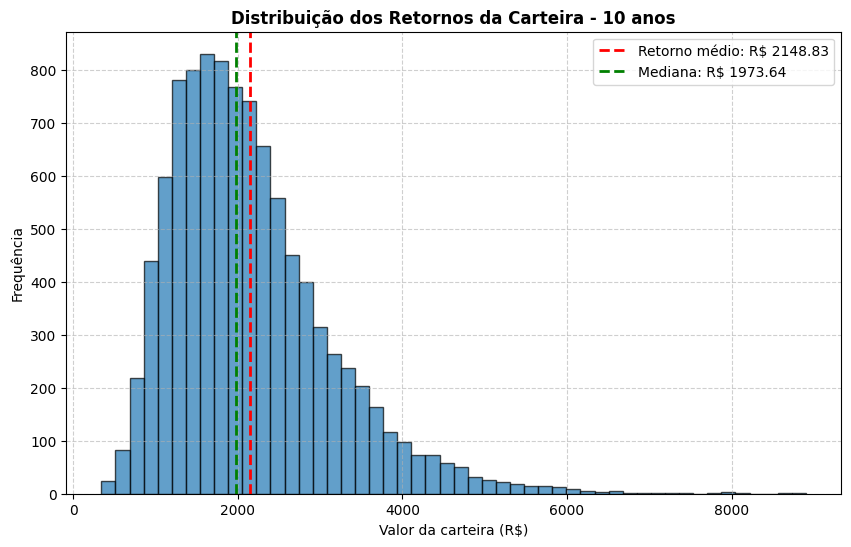

In [ ]:
# -- Geração e visualização do gráfico --
plt.figure(figsize=(10,6))                                                                              # cria uma figura de 10x6 pols
plt.hist(retorno_acumulado[:,-1], bins=50, edgecolor='black', alpha=0.7)                                # gera um gráfico do tipo histograma com 50 barras
plt.title("Distribuição dos Retornos da Carteira - 10 anos",weight='bold')                              # título do gráfico
plt.xlabel("Valor da carteira (R$)")                                                                    # título do eixo horizontal
plt.ylabel("Frequência")                                                                                # título do eixo vertical
plt.axvline(media, color='r', linestyle='dashed', linewidth=2, label=f"Retorno médio: R$ {media:.2f}")  # traça uma linha vertical tracejada indicando o retorno médio
plt.axvline(mediana, color='g', linestyle='dashed', linewidth=2, label=f"Mediana: R$ {mediana:.2f}")    # traça uma linha vertical tracejada indicando a mediana
plt.grid(True, linestyle='--', alpha=0.6)                                                               # exibe a grade
plt.legend()                                                                                            # mostra a legenda
plt.show()                                                                                              # mostra a figura